In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from collections import defaultdict as dd
import seaborn as sns
from sklearn.datasets import load_iris

from sklearn.linear_model import LogisticRegression as LogReg
from sklearn.preprocessing import PolynomialFeatures as PF
from sklearn.metrics import confusion_matrix as CM
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier as MLPc
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.metrics import precision_score as ps

from sklearn.model_selection import train_test_split

from sklearn.metrics import classification_report


from sklearn.preprocessing import OneHotEncoder as OHE
from sklearn.preprocessing import StandardScaler as SC
from sklearn.preprocessing import MinMaxScaler as MMS

###1. Постройте последний график методических указаний в исходном пространстве признаков.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


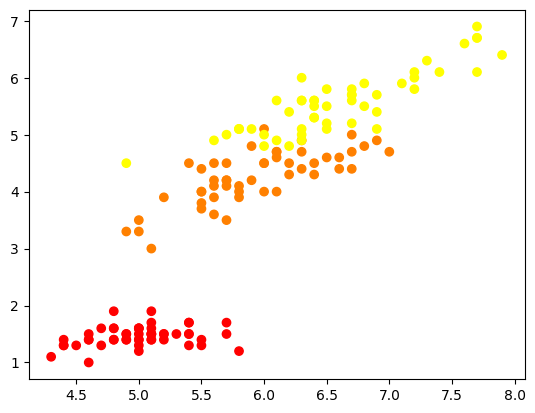

In [26]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
knn = KNN(n_neighbors=3)
knn.fit(x1, y)
pred = knn.predict(x1)

plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')

###2.Попробуйте обучить модель с другим значением k. Визуализируйте области классификации и сравните эффективности модели.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Real:


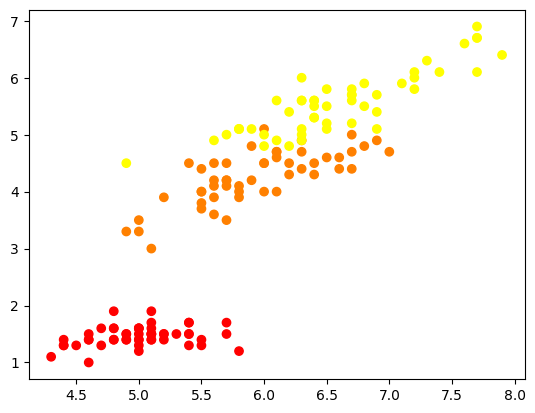

Predict:


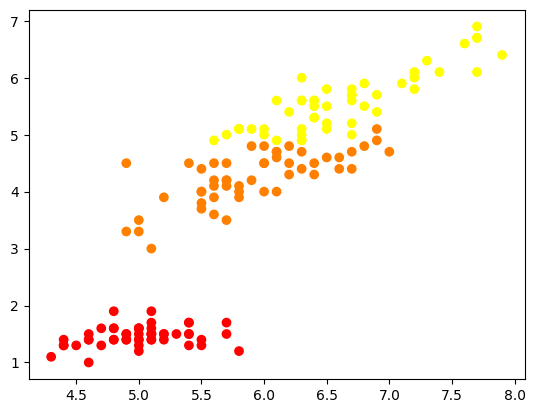

(150, 150, 2)


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


Compare:


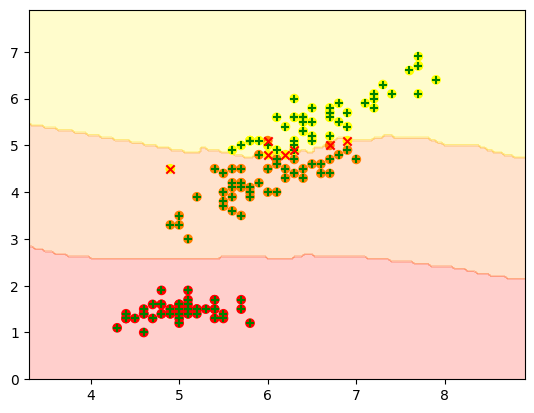

In [42]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
knn = KNN(n_neighbors=4)
knn.fit(x1, y)
pred = knn.predict(x1)

print(classification_report(y,pred))

print(f'Real:')
plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
plt.show()

print(f'Predict:')
plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=pred, cmap='autumn')
plt.show()


X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)
print(np.array([X0_grid, X1_grid]).T.shape)
Z = knn.predict(np.array([X0_grid.ravel(), X1_grid.ravel()]).T).reshape(X0_grid.shape)
plt.contourf(X0_grid, X1_grid, Z, cmap='autumn', alpha=0.2)


print(f'Compare:')
plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
correct = y==pred
plt.scatter( x1.iloc[correct, 0], x1.iloc[correct, 1], c='green', marker='+')
incorrect = y!=pred
plt.scatter( x1.iloc[incorrect, 0], x1.iloc[incorrect, 1], c='red', marker='x')
plt.show()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2





1 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      0.98      0.99        50
           2       0.98      1.00      0.99        50

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150
 



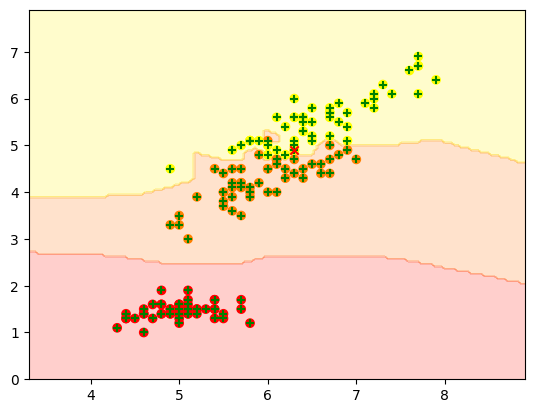




3 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 



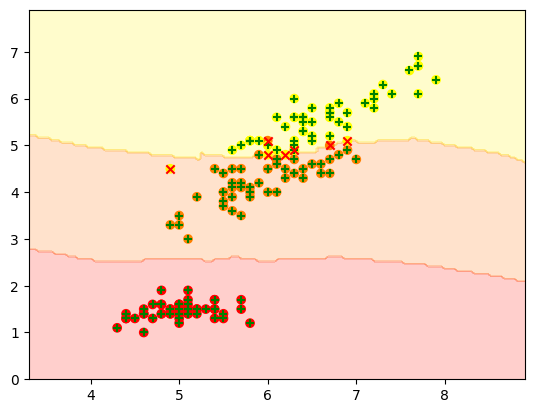




5 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 



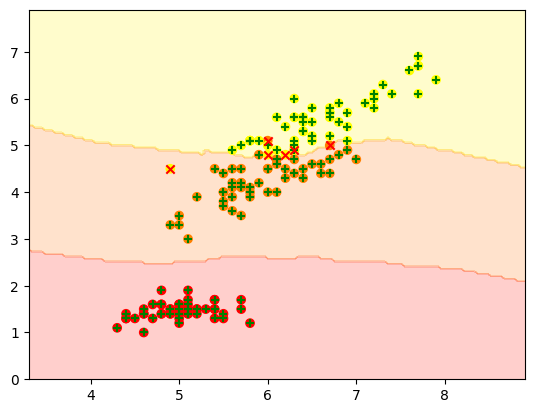




8 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 



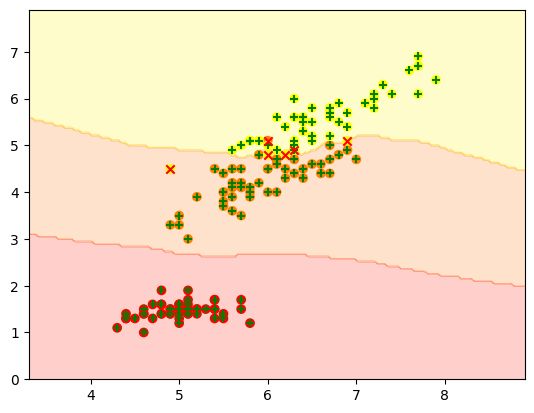




10 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.92      0.92        50
           2       0.92      0.92      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 



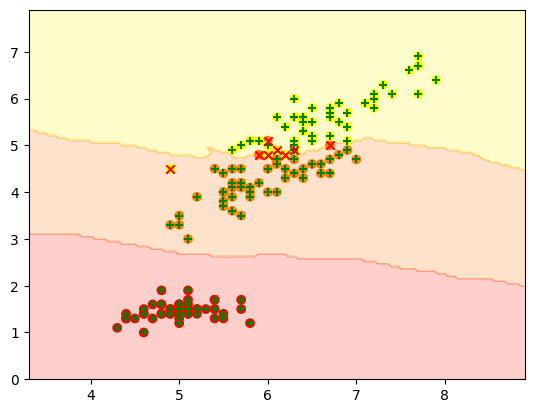




20 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 



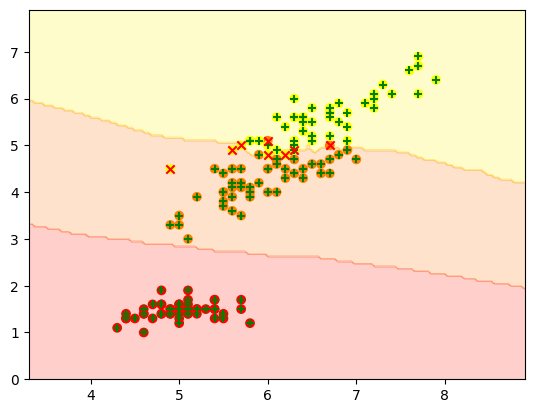




30 nearest:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 



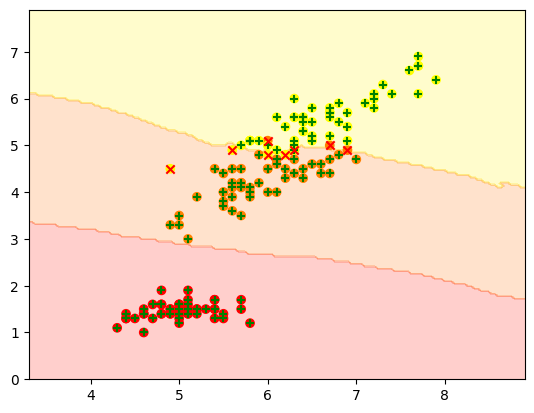

In [50]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)


def KNN_K_EXAMPLE(k):
  knn = KNN(n_neighbors=k)
  knn.fit(x1.values, y)
  pred = knn.predict(x1.values)
  print(f'\n\n\n{k} nearest:\n')
  print(classification_report(y,pred),'\n')
  Z = knn.predict(np.array([X0_grid.ravel(), X1_grid.ravel()]).T).reshape(X0_grid.shape)
  plt.contourf(X0_grid, X1_grid, Z, cmap='autumn', alpha=0.2)
  plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
  correct = y==pred
  plt.scatter( x1.iloc[correct, 0], x1.iloc[correct, 1], c='green', marker='+')
  incorrect = y!=pred
  plt.scatter( x1.iloc[incorrect, 0], x1.iloc[incorrect, 1], c='red', marker='x')
  plt.show()

for i in [1,3,5,8,10,20,30]:
  KNN_K_EXAMPLE(i)

###3.Подвигайте новое наблюдение в последнем пункте методических указаний. Сдвиньте его за пределы области определения выборки. Как меняется нормализованное значение?

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Compare:


<ipython-input-80-9193d1da9bbc>:31: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(obs[0][0],obs[0][1],c='blue',marker='*',cmap='autumn')


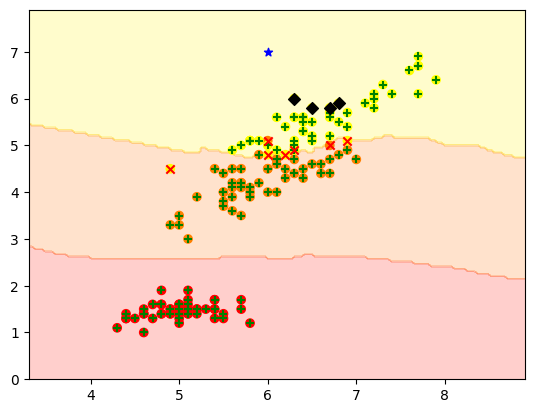

In [80]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
knn = KNN(n_neighbors=4)
knn.fit(x1.values, y)
pred = knn.predict(x1.values)

print(classification_report(y,pred))

X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

Z = knn.predict(np.array([X0_grid.ravel(), X1_grid.ravel()]).T).reshape(X0_grid.shape)
plt.contourf(X0_grid, X1_grid, Z, cmap='autumn', alpha=0.2)


print(f'Compare:')
plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
correct = y==pred
plt.scatter( x1.iloc[correct, 0], x1.iloc[correct, 1], c='green', marker='+')
incorrect = y!=pred
plt.scatter( x1.iloc[incorrect, 0], x1.iloc[incorrect, 1], c='red', marker='x')

#новое наблюдение
obs = [[6,7]]
#y_obs = knn.predict(obs)
plt.scatter(obs[0][0],obs[0][1],c='blue',marker='*',cmap='autumn')
ind = knn.kneighbors(obs)[1][0]
x_neig = x1.loc[ind]

plt.scatter(x_neig.iloc[:,0].values,x_neig.iloc[:,1].values,c='black',marker='D')

plt.show()

In [88]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
knn = KNN(n_neighbors=4)
knn.fit(x1.values, y)
pred = knn.predict(x1.values)

print(classification_report(y,pred))

def EXPERIMENT(obs):
  obs=[obs]

  X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
  X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
  X0_grid, X1_grid = np.meshgrid(X0, X1)

  Z = knn.predict(np.array([X0_grid.ravel(), X1_grid.ravel()]).T).reshape(X0_grid.shape)
  plt.contourf(X0_grid, X1_grid, Z, cmap='autumn', alpha=0.2)


  plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
  correct = y==pred
  plt.scatter( x1.iloc[correct, 0], x1.iloc[correct, 1], c='green', marker='+')
  incorrect = y!=pred
  plt.scatter( x1.iloc[incorrect, 0], x1.iloc[incorrect, 1], c='red', marker='x')

  #новое наблюдение
  #obs = [[6,7]]
  y_obs = knn.predict(obs)
  plt.scatter(obs[0][0],obs[0][1],c='blue',marker='*')
  ind = knn.kneighbors(obs)[1][0]
  x_neig = x1.loc[ind]

  plt.scatter(x_neig.iloc[:,0].values,x_neig.iloc[:,1].values,c='black',marker='D')

  plt.show()
  print(f'Coordinates: {obs[0]}\nClass predicted = {y_obs}')

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150



Классы и их цвета:

2 - желтый


1 - оранжевый


0 - красный

In [96]:
for i in range(2,12):
  for j in range(-2,10):
    EXPERIMENT([i,j])

Output hidden; open in https://colab.research.google.com to view.

###4.Поэкспериментируйте с разными метриками расстояния. Визуализируйте ближайших соседей нового объекта при разных метриках расстояния.

In [103]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())

def EXPERIMENT_DIST(obs, dist):
  knn = KNN(n_neighbors=4,metric=dist)
  knn.fit(x1.values, y)
  pred = knn.predict(x1.values)


  obs=[obs]

  X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
  X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
  X0_grid, X1_grid = np.meshgrid(X0, X1)

  Z = knn.predict(np.array([X0_grid.ravel(), X1_grid.ravel()]).T).reshape(X0_grid.shape)
  plt.contourf(X0_grid, X1_grid, Z, cmap='autumn', alpha=0.2)


  plt.scatter(x1.iloc[:, 0], x1.iloc[:, 1], c=y, cmap='autumn')
  correct = y==pred
  plt.scatter( x1.iloc[correct, 0], x1.iloc[correct, 1], c='green', marker='+')
  incorrect = y!=pred
  plt.scatter( x1.iloc[incorrect, 0], x1.iloc[incorrect, 1], c='red', marker='x')

  y_obs = knn.predict(obs)
  plt.scatter(obs[0][0],obs[0][1],c='blue',marker='*')
  ind = knn.kneighbors(obs)[1][0]
  x_neig = x1.loc[ind]

  plt.scatter(x_neig.iloc[:,0].values,x_neig.iloc[:,1].values,c='black',marker='D')

  plt.show()
  print(classification_report(y,pred))
  print(f'Coordinates: {obs[0]}\nClass predicted = {y_obs}\nDistance function: {dist}\n\n\n')

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


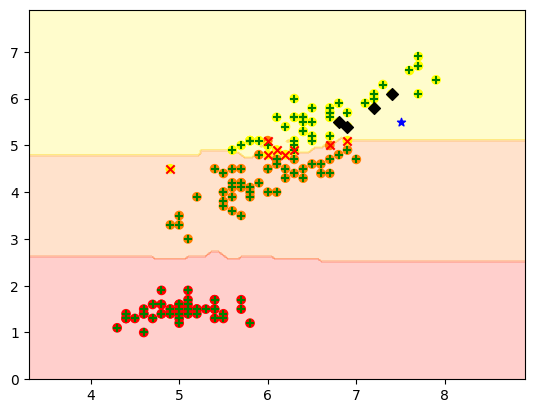

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: cityblock





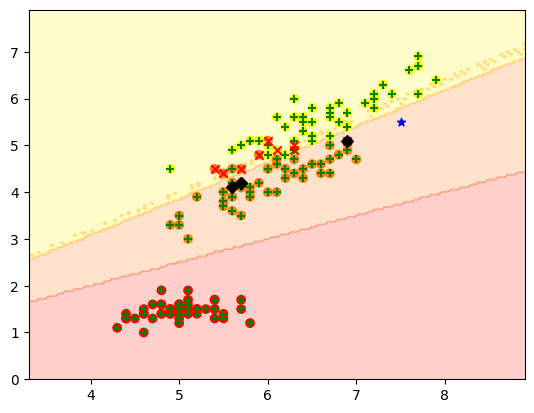

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.88      0.91        50
           2       0.89      0.94      0.91        50

    accuracy                           0.94       150
   macro avg       0.94      0.94      0.94       150
weighted avg       0.94      0.94      0.94       150

Coordinates: [7.5, 5.5]
Class predicted = [1]
Distance function: cosine





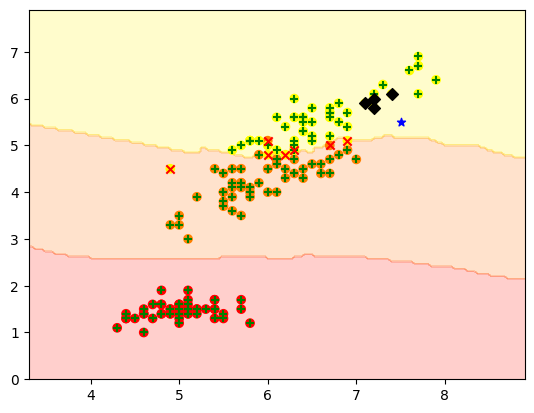

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: euclidean





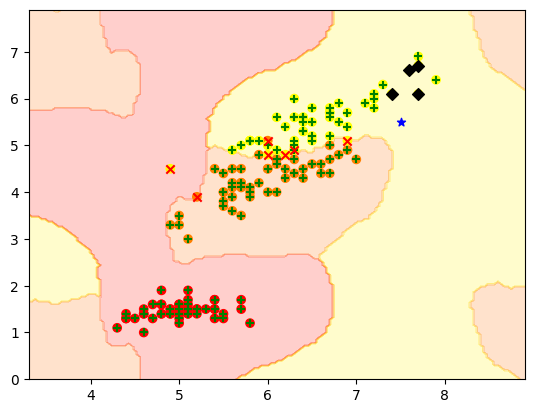

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       0.94      0.94      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: haversine





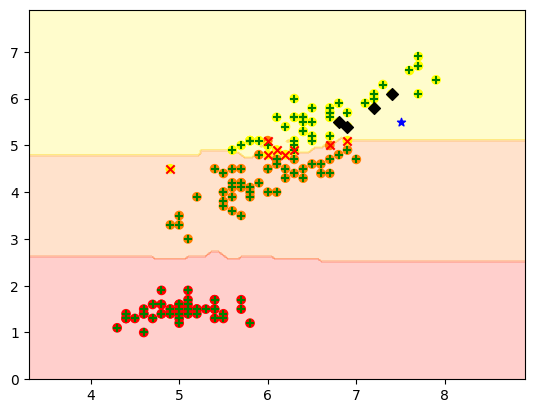

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: l1





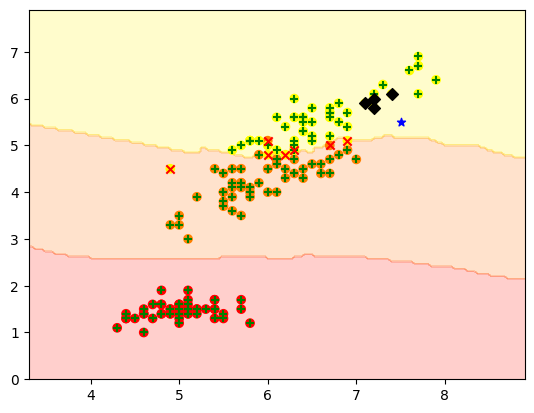

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.94      0.93        50
           2       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: l2





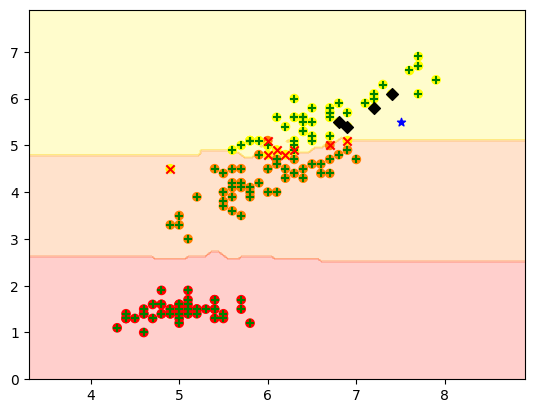

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: manhattan





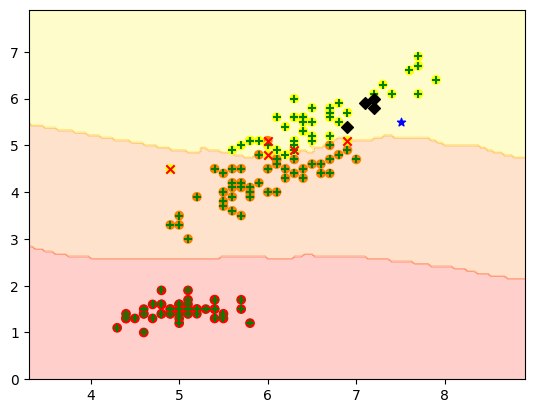

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.96      0.95        50
           2       0.96      0.94      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150

Coordinates: [7.5, 5.5]
Class predicted = [2]
Distance function: nan_euclidean





In [104]:
l = ['cityblock','cosine','euclidean','haversine','l1','l2','manhattan','nan_euclidean']
for i in l:
  EXPERIMENT_DIST([7.5,5.5],i)

###5.Обучите модель на полном датасете. Сравните ее эффективность с описанной в методических указаниях. Попробуйте разные значения k.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2





1 nearest:



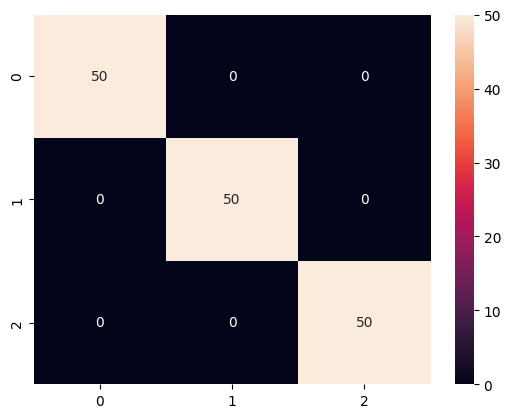

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        50

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150
 




2 nearest:



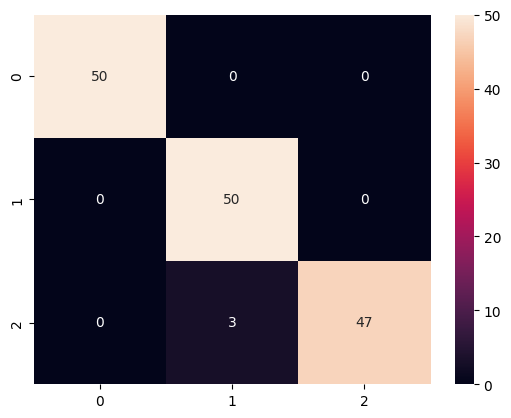

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      1.00      0.97        50
           2       1.00      0.94      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




3 nearest:



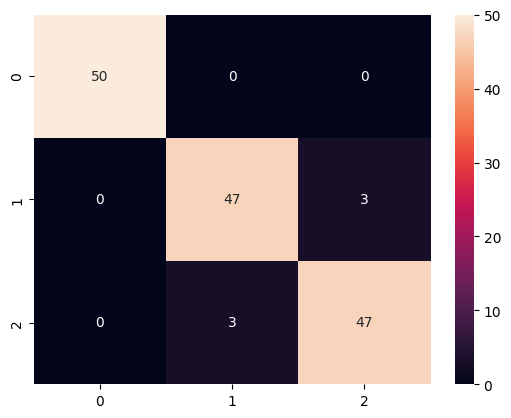

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




4 nearest:



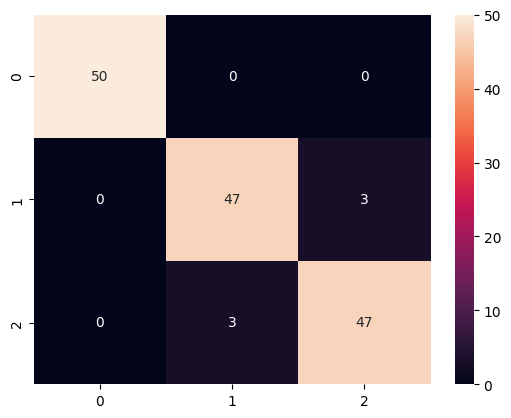

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




5 nearest:



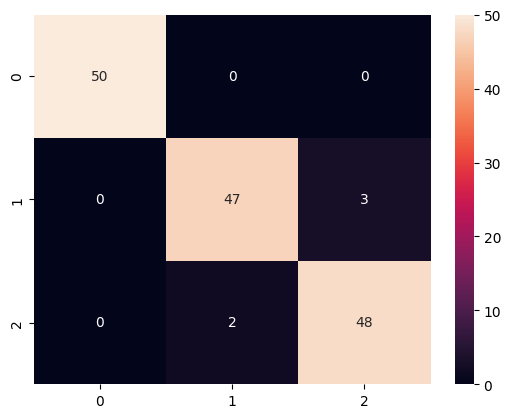

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.94      0.95        50
           2       0.94      0.96      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




6 nearest:



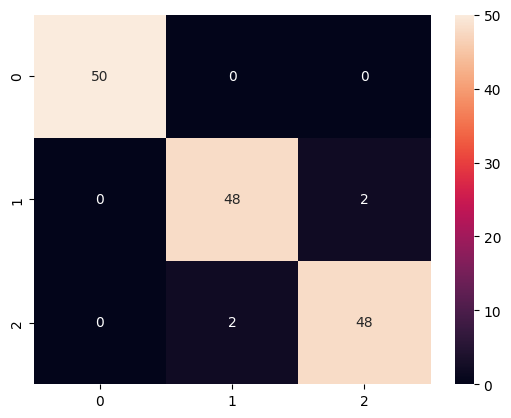

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




7 nearest:



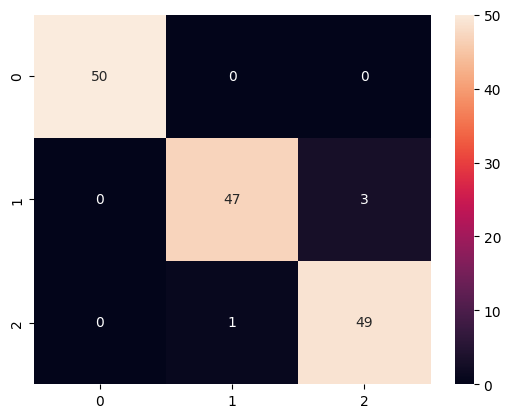

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.94      0.96        50
           2       0.94      0.98      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




8 nearest:



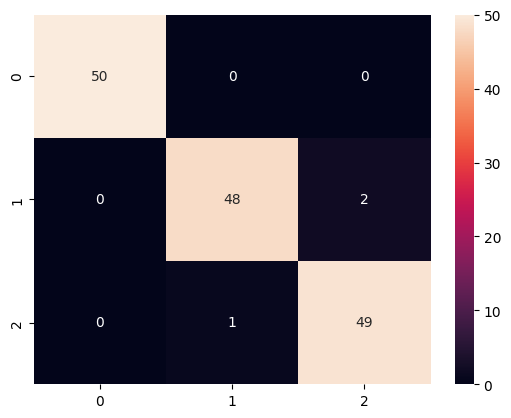

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




9 nearest:



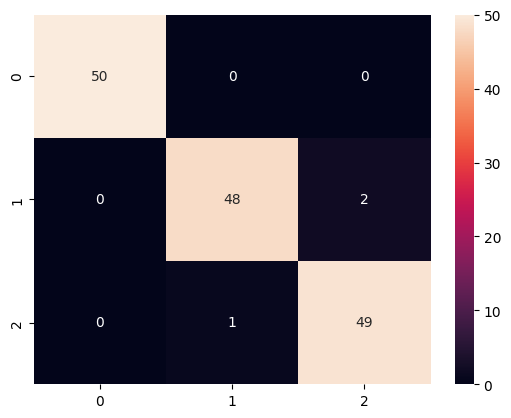

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




10 nearest:



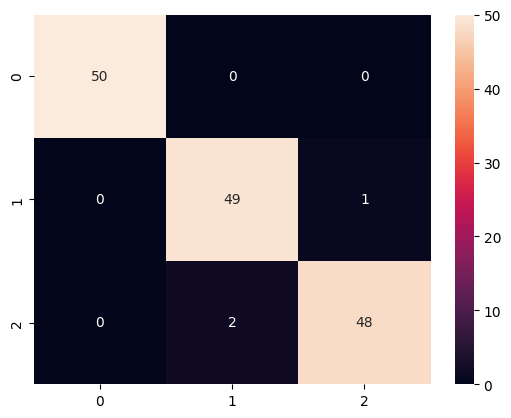

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.98      0.97        50
           2       0.98      0.96      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




11 nearest:



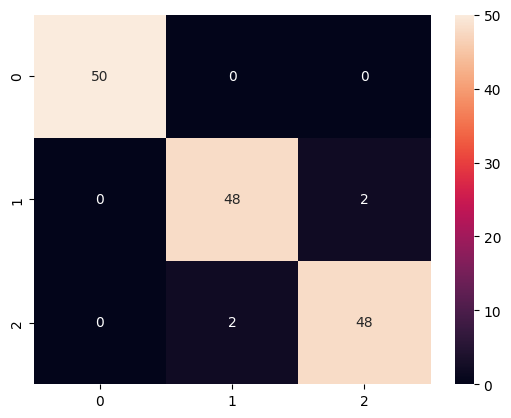

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




12 nearest:



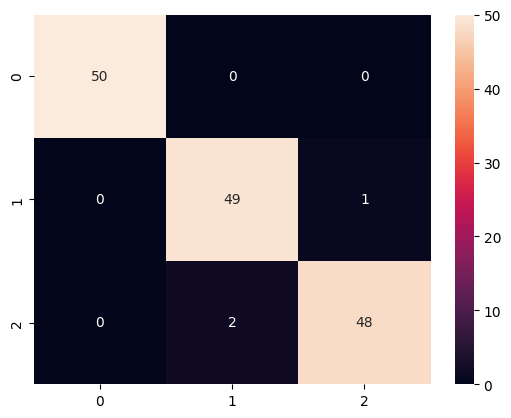

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.98      0.97        50
           2       0.98      0.96      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




13 nearest:



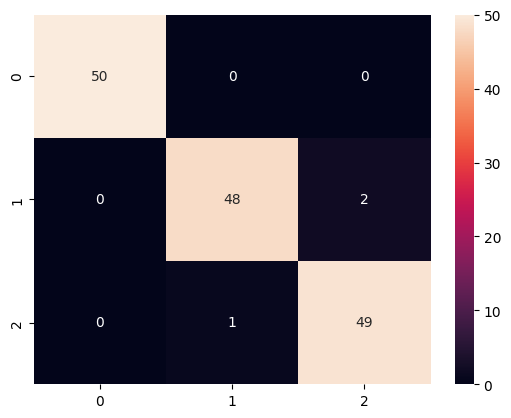

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




14 nearest:



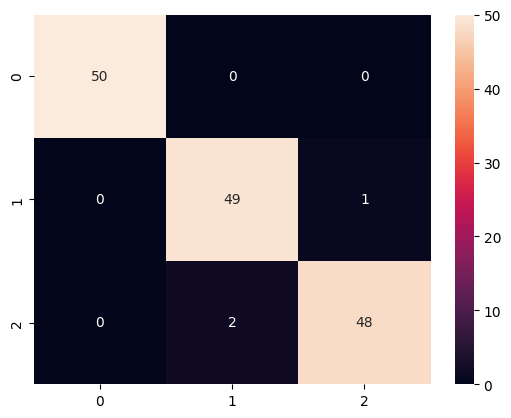

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.98      0.97        50
           2       0.98      0.96      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




15 nearest:



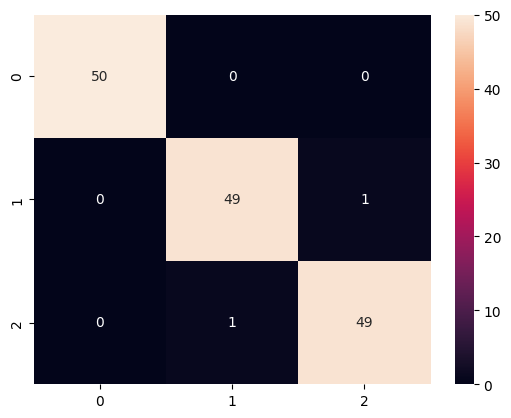

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.98      0.98        50
           2       0.98      0.98      0.98        50

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150
 




16 nearest:



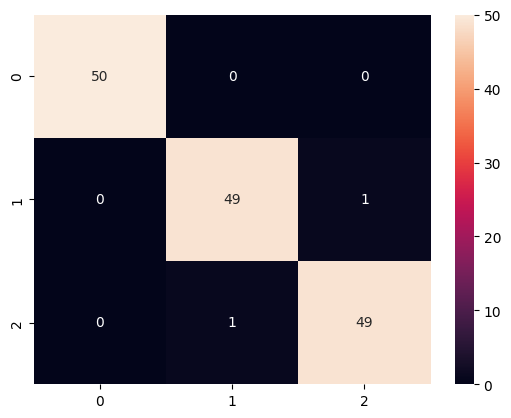

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.98      0.98        50
           2       0.98      0.98      0.98        50

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150
 




17 nearest:



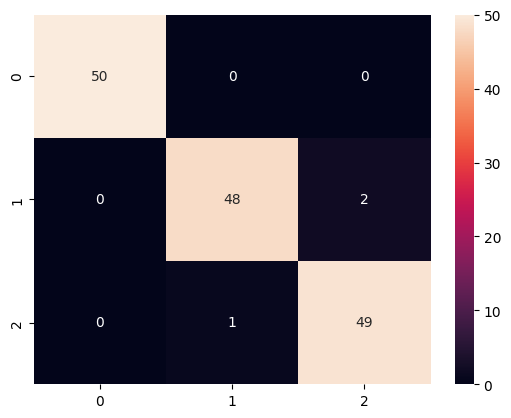

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




18 nearest:



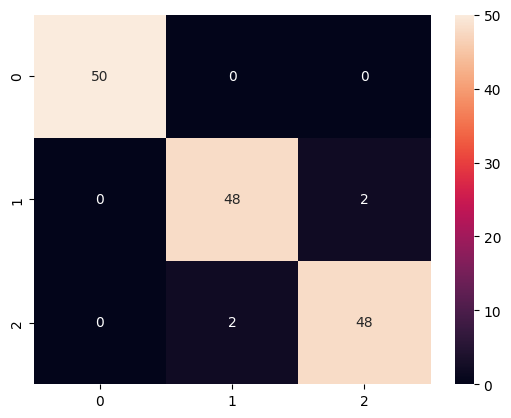

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




19 nearest:



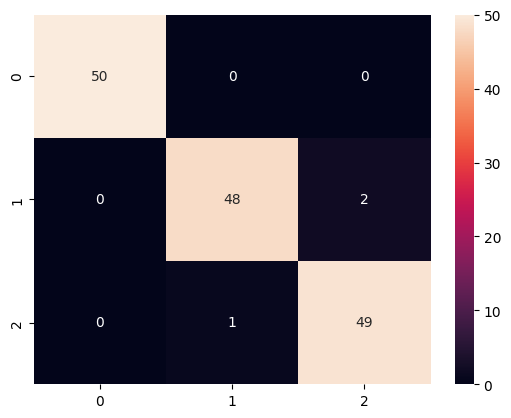

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




20 nearest:



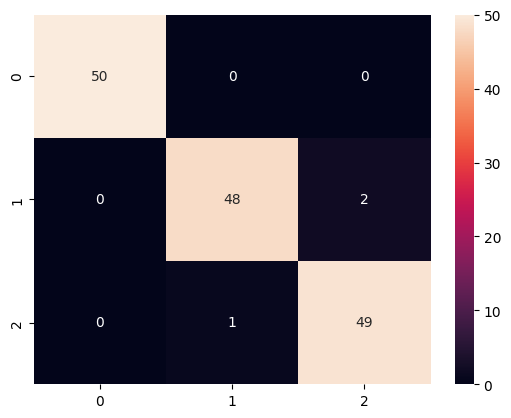

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




21 nearest:



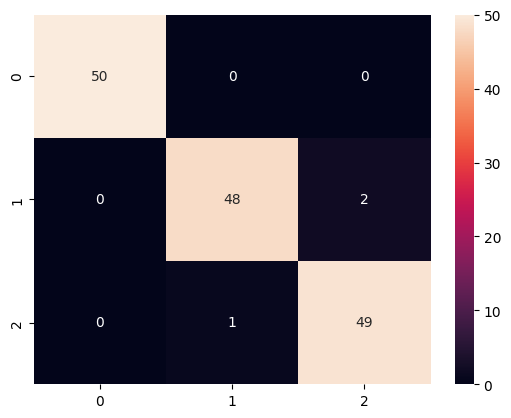

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




22 nearest:



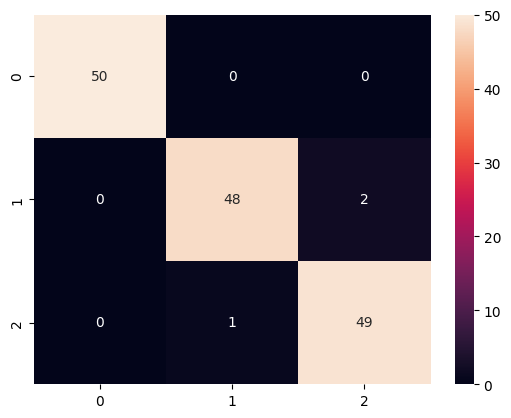

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




23 nearest:



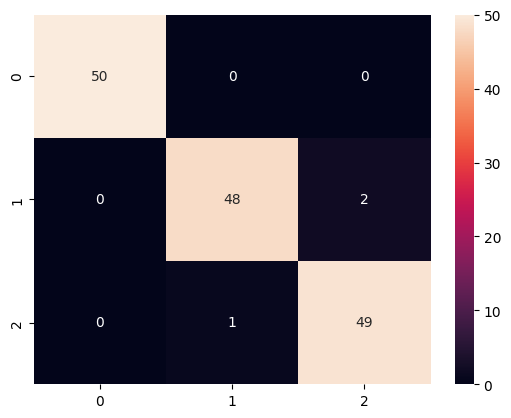

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




24 nearest:



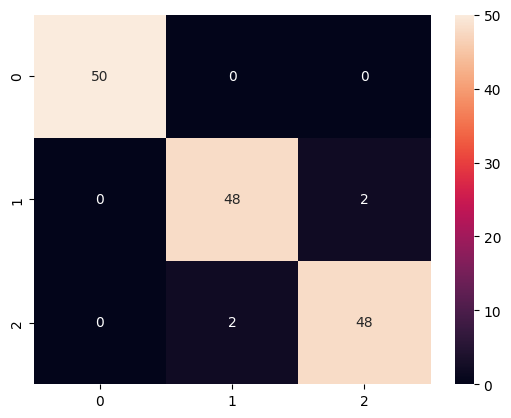

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




25 nearest:



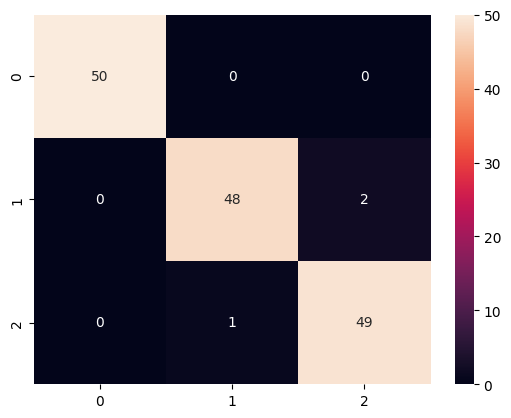

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.98      0.96      0.97        50
           2       0.96      0.98      0.97        50

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150
 




26 nearest:



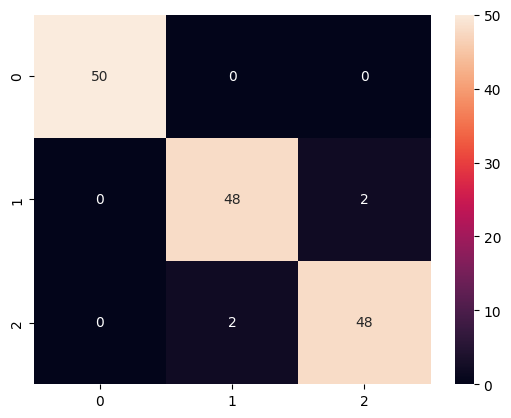

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




27 nearest:



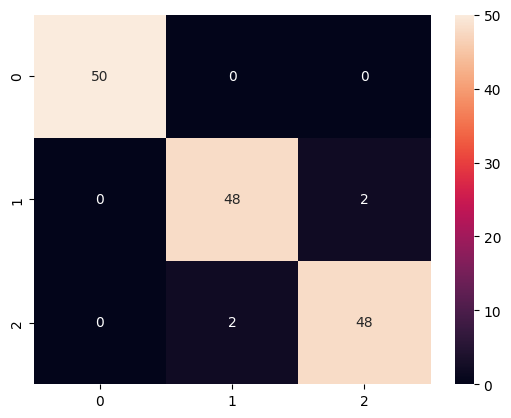

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




28 nearest:



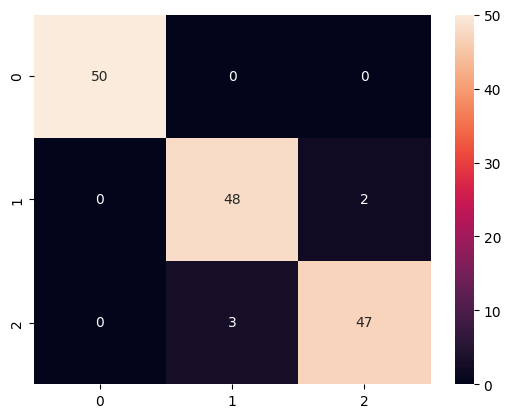

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.96      0.95        50
           2       0.96      0.94      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




29 nearest:



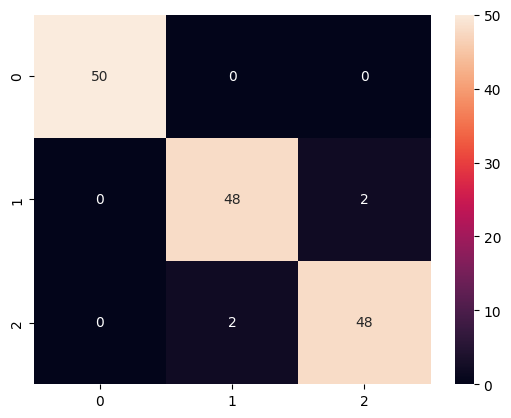

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.96      0.96        50
           2       0.96      0.96      0.96        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 




30 nearest:



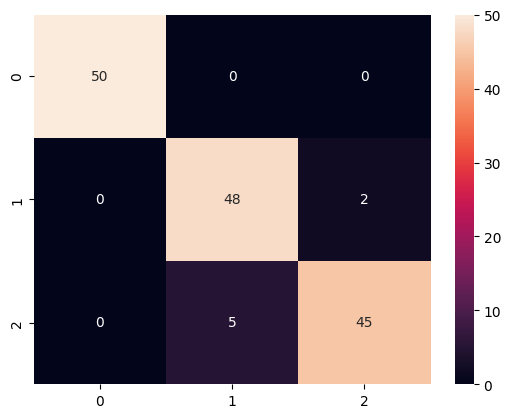

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




31 nearest:



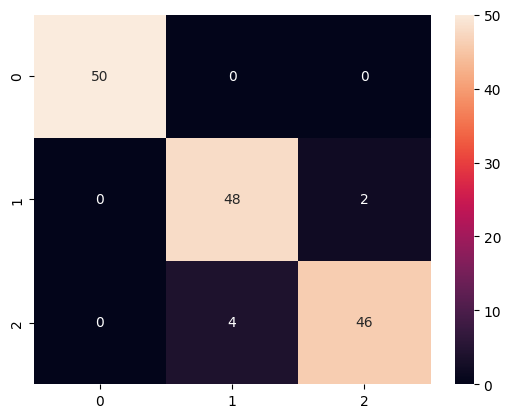

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




32 nearest:



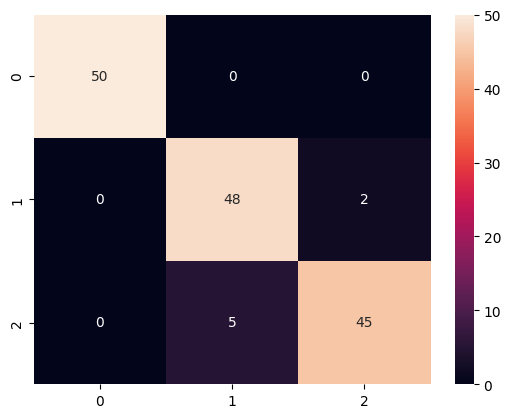

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




33 nearest:



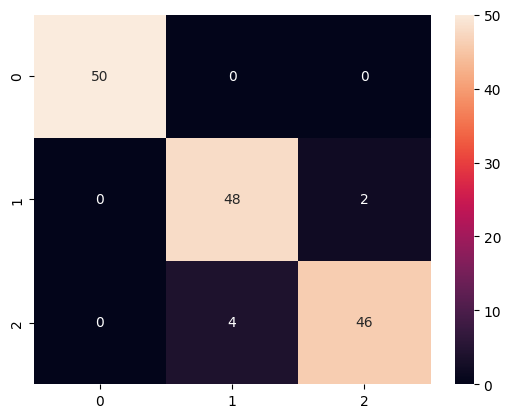

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




34 nearest:



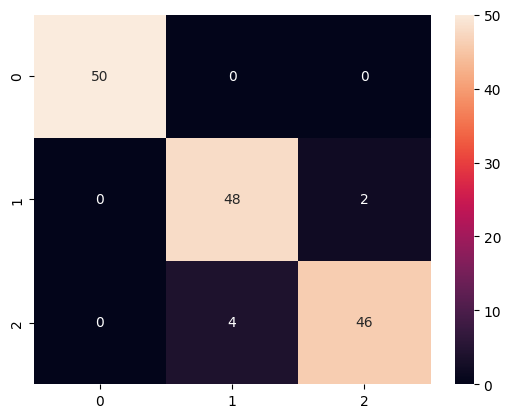

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




35 nearest:



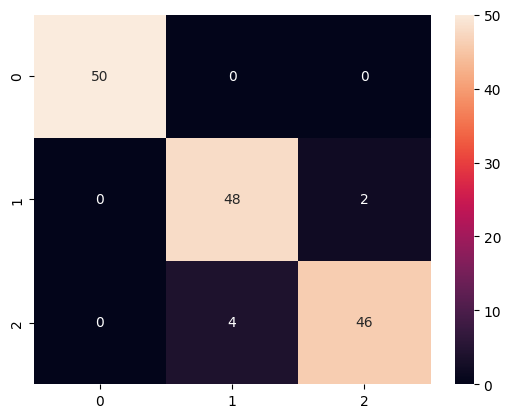

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




36 nearest:



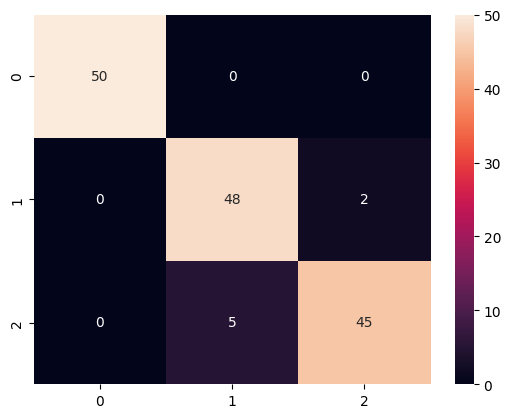

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




37 nearest:



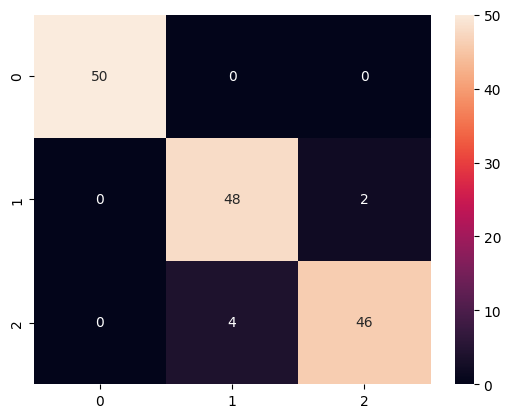

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 




38 nearest:



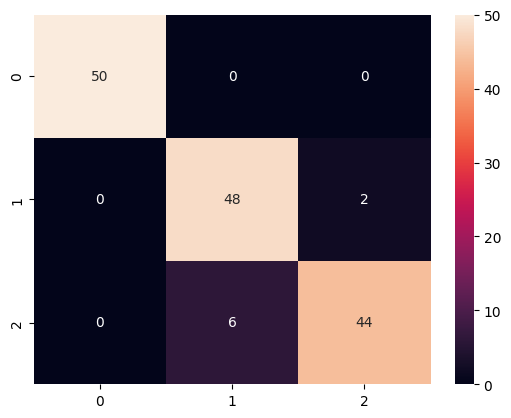

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.89      0.96      0.92        50
           2       0.96      0.88      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




39 nearest:



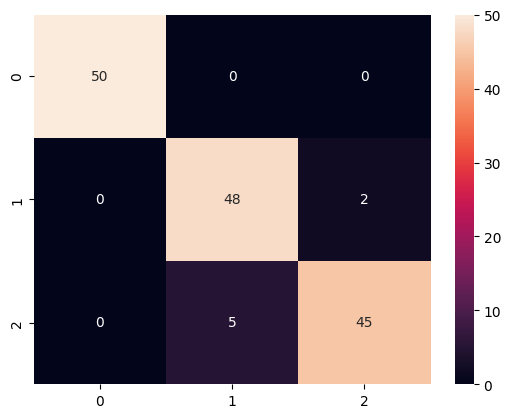

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




40 nearest:



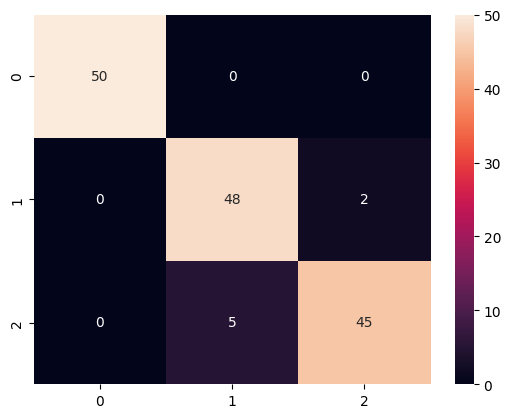

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




41 nearest:



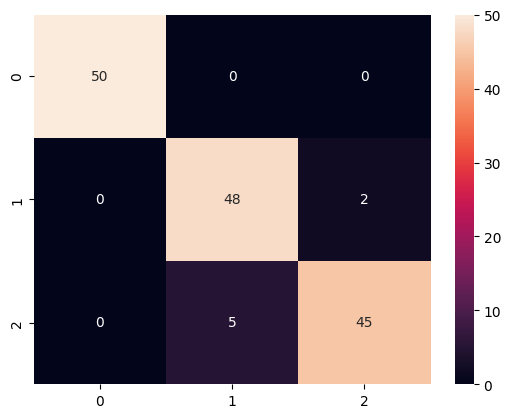

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




42 nearest:



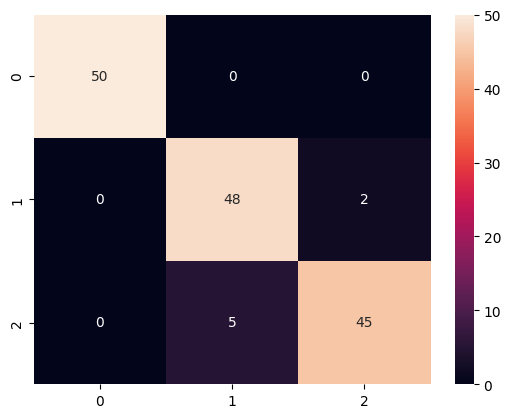

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




43 nearest:



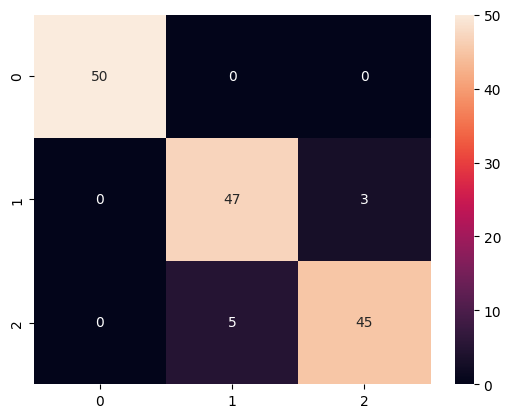

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.90      0.94      0.92        50
           2       0.94      0.90      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




44 nearest:



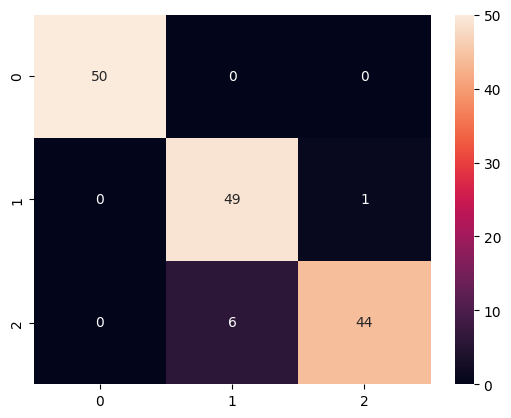

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.89      0.98      0.93        50
           2       0.98      0.88      0.93        50

    accuracy                           0.95       150
   macro avg       0.96      0.95      0.95       150
weighted avg       0.96      0.95      0.95       150
 




45 nearest:



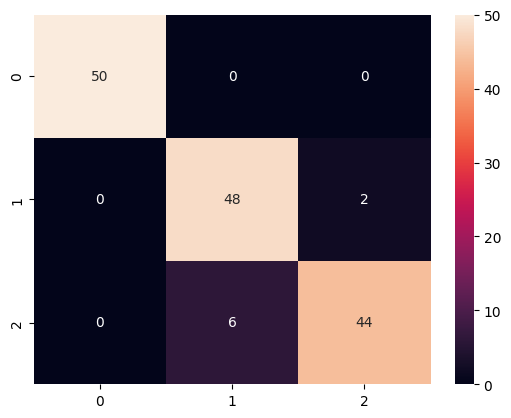

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.89      0.96      0.92        50
           2       0.96      0.88      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




46 nearest:



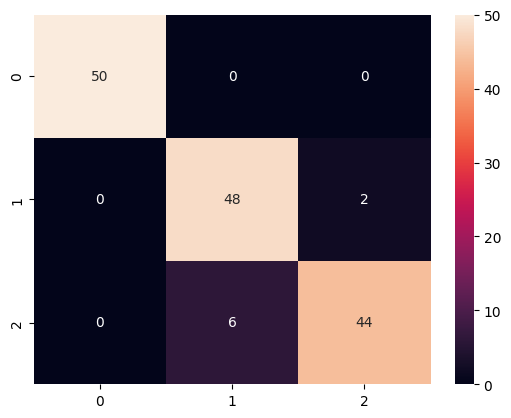

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.89      0.96      0.92        50
           2       0.96      0.88      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




47 nearest:



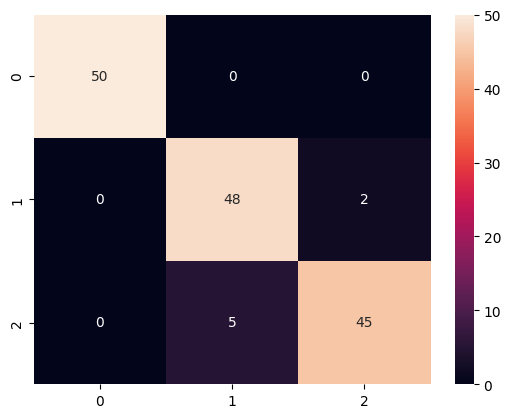

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.91      0.96      0.93        50
           2       0.96      0.90      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




48 nearest:



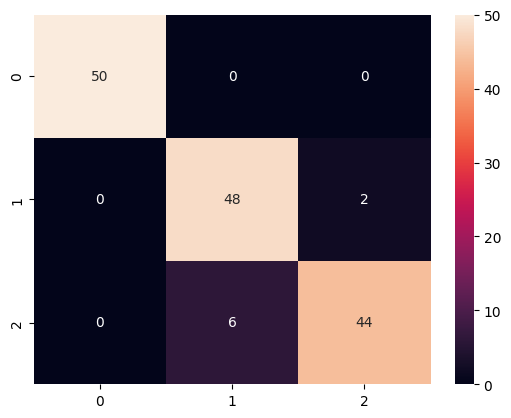

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.89      0.96      0.92        50
           2       0.96      0.88      0.92        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150
 




49 nearest:



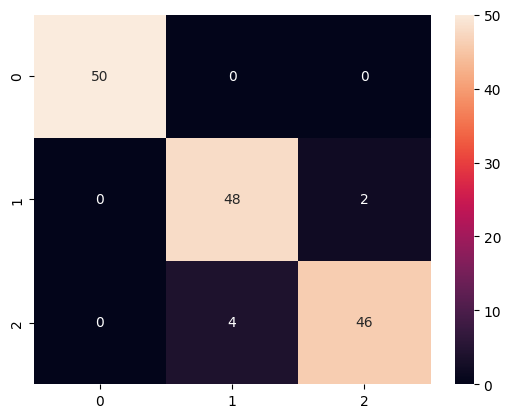

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.92      0.96      0.94        50
           2       0.96      0.92      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150
 



In [108]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)


def KNN_K_EXAMPLE(k):
  knn = KNN(n_neighbors=k)
  knn.fit(x.values, y)
  pred = knn.predict(x.values)
  print(f'\n\n\n{k} nearest:\n')
  sns.heatmap(CM(y,pred), annot=True, fmt ='d')
  plt.show()
  print(classification_report(y,pred),'\n')


for i in range(1,50):
  KNN_K_EXAMPLE(i)

###6.Попробуйте в модели на полном датасете взвешенный алгоритм (аргумент weights объекта KNeighborsClassifier). Сравние его точность с равномерным вариантом.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2





5 nearest:



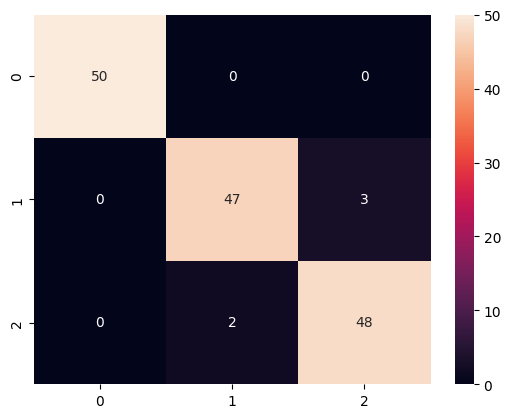

Weights: uniform
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.96      0.94      0.95        50
           2       0.94      0.96      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150
 





5 nearest:



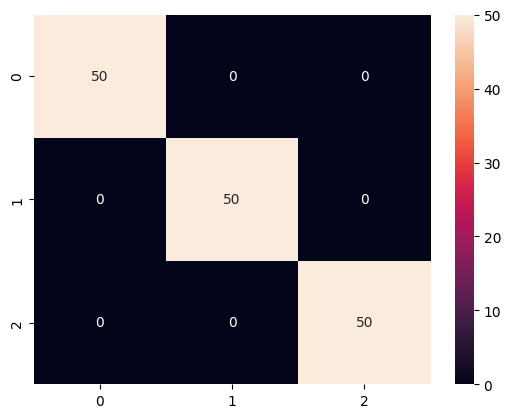

Weights: distance
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        50

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150
 



In [110]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

knn = KNN(n_neighbors=5,weights='uniform')
knn.fit(x.values, y)
pred = knn.predict(x.values)
print(f'\n\n\n{5} nearest:\n')
sns.heatmap(CM(y,pred), annot=True, fmt ='d')
plt.show()
print(f'Weights: uniform')
print(classification_report(y,pred),'\n\n')

knn = KNN(n_neighbors=5,weights='distance')
knn.fit(x.values, y)
pred = knn.predict(x.values)
print(f'\n\n\n{5} nearest:\n')
sns.heatmap(CM(y,pred), annot=True, fmt ='d')
plt.show()
print(f'Weights: distance')
print(classification_report(y,pred),'\n')

###7.Постройте график точности (accuracy) модели в зависимости от значения k. Сделайте вывод.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


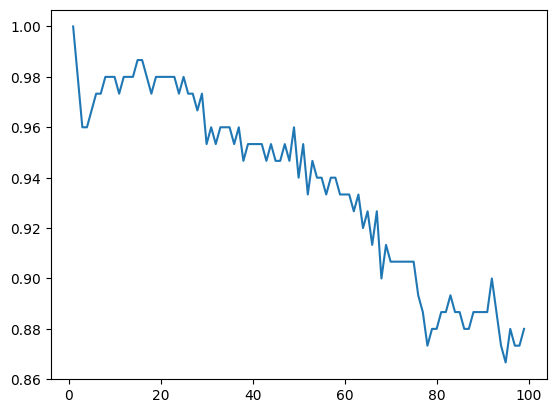

In [122]:
iris = load_iris()
features = iris.data
x,y  = load_iris(return_X_y = True)
x = pd.DataFrame(x, columns = iris.feature_names)
x1 = x[['sepal length (cm)','petal length (cm)']]
display(x.head())
X0 = np.linspace(x1.iloc[:, 0].min()-1,x1.iloc[:, 0].max()+1, x1.shape[0])
X1 = np.linspace(x1.iloc[:, 1].min()-1,x1.iloc[:, 1].max()+1, x1.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)


def KNN_K_EXAMPLE_ACC(k):
  knn = KNN(n_neighbors=k)
  knn.fit(x.values, y)
  pred = knn.predict(x.values)
  return ps(y,pred,average='micro')

x_plot=list(range(1,100))
y_plot=[]
for i in x_plot:
  y_plot.append(KNN_K_EXAMPLE_ACC(i))
plt.plot(x_plot,y_plot)
plt.show()

###8.Выберите датасет и постройте регрессию при помощи метода ближайших соседей.

In [174]:
from sklearn.datasets import load_diabetes
x,y=load_diabetes(return_X_y=True)
x=pd.DataFrame(x,columns=load_diabetes().feature_names)
display(x.head())
print(x.shape)
knn = KNNR(n_neighbors=10,weights='distance')
knn.fit(x.values, y)
pred = knn.predict(x.values)
knn.score(X_test,Y_test)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


(442, 10)


1.0

In [203]:
from sklearn.datasets import load_diabetes
x,y=load_diabetes(return_X_y=True)
sc = SC()
x = sc.fit_transform(x)
sc = SC()
y = pd.DataFrame(y)
y = sc.fit_transform(y)

X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.1, random_state=42)

knn = KNNR(n_neighbors=20,weights='distance')
knn.fit(X_train, np.float64(Y_train))
pred = knn.predict(X_test)
knn.score(X_test,Y_test)

0.547062824084457